# CS771 (Autumn 2026) Mini-Project 1: Next-Day PM2.5 Forecasting and Heatmap Generation

This self-contained notebook implements and documents the complete workflow for **Parts 0 through 5**:
- **Part 0**: Cleaning and diagnosing the raw Kanpur sensor dataset (`kanpur_pm25_raw_jul_aug_2026.csv`), generating `kanpur_hourly_clean.csv`, performing the cross-family calibration test, and analyzing the IST diurnal cycle.
- **Part 1**: Implementing the Persistence baseline and the 29-feature `Ridge(alpha=1.0)` baseline on the Bihar network (`bihar_pm25_hourly_jan_nov_2024.csv`), and comparing RMSE vs. MAE behavior.
- **Part 2**: Feature engineering across 5 retained spatio-temporal feature groups (plus 1 ablated static/calendar group), model comparison (Ridge vs. Huber vs. HistGradientBoosting), and leave-one-group-out ablation study.
- **Part 3**: Evaluating forecast accuracy across lead times of 1, 3, 6, 12, and 24 hours, and explaining the non-monotonic persistence hump via the Bihar diurnal cycle.
- **Part 4**: Inverse-distance weighting ($p=2$) spatial interpolation onto the $0.05^\circ$ Bihar grid (`bihar_grid_005deg.csv`), visual comparison on three representative validation days, and analysis of station RMSE vs. map RMSE and pattern correlation.
- **Part 5**: Refitting the final Part 2 model on all targets up to 30 November 2024 and verifying `submission/forecast.py` via `starter/check_submission.py`.

In [1]:
from pathlib import Path
import shutil
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, LinearRegression, SGDRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
np.random.seed(42)

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.dpi": 120,
})

ROOT = Path(".").resolve()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
SUB_DIR = ROOT / "submission"
SUB_DIR.mkdir(exist_ok=True)
print("Working directory:", ROOT)

Working directory: D:\IITK\5th-Sem\CS771\CS771\mp1-package\mp1-package


---
## Part 0: Cleaning a Raw Sensor Dataset (Kanpur)

### 0.1 Understand the Format & Sensor ID Families
We inspect `data/kanpur_pm25_raw_jul_aug_2026.csv`, which contains 5,952 rows on a 15-minute UTC grid from `2026-07-01 00:00:00Z` to `2026-08-31 23:45:00Z` across **76 sensors** (3 columns per sensor: `<id>_latitude`, `<id>_longitude`, `<id>_pm25`).

In [2]:
raw_kanpur = pd.read_csv(DATA_DIR / "kanpur_pm25_raw_jul_aug_2026.csv")
ts_utc = pd.to_datetime(raw_kanpur["timestamp_utc"])
hour_start = ts_utc.dt.floor("h")
minute_val = ts_utc.dt.minute

pm_cols = [c for c in raw_kanpur.columns if c.endswith("_pm25")]
sensor_ids = [c[:-5] for c in pm_cols]
print(f"Raw table shape: {raw_kanpur.shape} | Total sensors: {len(sensor_ids)}")

sensor_meta = []
for sid in sensor_ids:
    pm = raw_kanpur[f"{sid}_pm25"].dropna()
    lat = raw_kanpur[f"{sid}_latitude"].dropna()
    lon = raw_kanpur[f"{sid}_longitude"].dropna()
    ts_s = ts_utc[raw_kanpur[f"{sid}_pm25"].notna()]
    diffs = ts_s.diff().dt.total_seconds() / 60.0
    is_int = bool(np.all(np.isclose(pm % 1, 0)))
    sensor_meta.append({
        "sensor_id": sid,
        "id_len": len(sid),
        "n_15m_reports": len(pm),
        "median_interval_min": diffs.median(),
        "lat_span": lat.max() - lat.min(),
        "lon_span": lon.max() - lon.min(),
        "is_integer": is_int,
        "mean_pm25": pm.mean(),
        "median_pm25": pm.median(),
        "min_pm25": pm.min(),
        "max_pm25": pm.max(),
    })

meta_df = pd.DataFrame(sensor_meta)
print("\nSensor summary by ID length:")
display(meta_df.groupby("id_len")[["n_15m_reports", "median_interval_min", "lat_span", "lon_span", "is_integer", "mean_pm25", "median_pm25", "max_pm25"]].agg(["count", "mean", "median", "min", "max"]))

Raw table shape: (5952, 229) | Total sensors: 76



Sensor summary by ID length:


n_15m_reports                                  median_interval_min  \
               count         mean  median   min   max               count   
id_len                                                                      
8                 31  1009.290323  1014.0   791  1232                  31   
10                44  1127.977273  1183.5   762  1306                  44   
12                 1  4843.000000  4843.0  4843  4843                   1   

                                 ... median_pm25                        \
        mean median   min   max  ...       count       mean     median   
id_len                           ...                                     
8       60.0   60.0  60.0  60.0  ...          31  32.976189  31.887583   
10      60.0   60.0  60.0  60.0  ...          44  35.863636  37.000000   
12      15.0   15.0  15.0  15.0  ...           1  25.000000  25.000000   

                       max_pm25                                               
           min     max    count        mean   median         min         max  
id_len                                                                        
8       24.324  44.485       31  253.269516  201.262  102.229333  617.831333  
10       0.000  49.000       44  376.318182  216.000   88.000000  999.000000  
12      25.000  25.000        1  101.000000  101.000  101.000000  101.000000  

[3 rows x 40 columns]

**Key Findings from Format Inspection (Part 0.1):**
1. **Number of sensors**: **76 sensors** split into three ID styles:
   - **44 sensors with 10-digit numeric IDs** (e.g., `1203260058`): report once per hour at minute `:00` (median interval 60 min; 762–1,306 reports out of 1,488 hours). All 44 report **integer-only** $\text{PM}_{2.5}$ values ($1\,\mu\text{g/m}^3$ resolution), with raw mean $41.83\,\mu\text{g/m}^3$ (median $35.86\,\mu\text{g/m}^3$) and saturation error codes at `999.0`.
   - **31 sensors with 8-character alphanumeric IDs** (e.g., `01DQW5QE`): report once per hour at minute `:00` (median interval 60 min; 791–1,232 reports). All 31 report **continuous floating-point** values (up to 6 decimal places), with raw mean $36.93\,\mu\text{g/m}^3$ (median $32.98\,\mu\text{g/m}^3$) and no `999.0` error codes.
   - **1 sensor with a 12-character hex MAC-style ID** (`AC0BFBE34CC7`): reports every **15 minutes** at `:00, :15, :30, :45` (4,843 reports; median interval 15 min) in integer resolution, at a lower typical level (mean $24.40\,\mu\text{g/m}^3$, median $25.00\,\mu\text{g/m}^3$).
2. **Sensor movement**: **No sensor moves** (`lat_span == 0` and `lon_span == 0` across all 5,952 timestamps for all 76 sensors). Note that latitude/longitude are populated on all 5,952 rows even when `pm25` is `NaN`.

### 0.2 Reshape to Hourly Long Table & Compare with Keeping `:00`

In [3]:
hourly_parts = []
for sid in sensor_ids:
    sub = pd.DataFrame({
        "sensor_id": sid,
        "timestamp_utc": hour_start,
        "minute": minute_val,
        "latitude": raw_kanpur[f"{sid}_latitude"],
        "longitude": raw_kanpur[f"{sid}_longitude"],
        "pm25": raw_kanpur[f"{sid}_pm25"],
    }).dropna(subset=["pm25"])
    hourly_parts.append(sub)

long_15m = pd.concat(hourly_parts, ignore_index=True)
hourly = (
    long_15m.groupby(["sensor_id", "timestamp_utc"], as_index=False)
    .agg({"latitude": "mean", "longitude": "mean", "pm25": "mean"})
    .sort_values(["sensor_id", "timestamp_utc"])
    .reset_index(drop=True)
)

only_00 = long_15m[long_15m["minute"] == 0][["sensor_id", "timestamp_utc", "pm25"]].rename(columns={"pm25": "pm25_at_00"})
comp_00 = pd.merge(hourly, only_00, on=["sensor_id", "timestamp_utc"], how="left")
diff_00 = comp_00[comp_00["pm25"] != comp_00["pm25_at_00"]]

print(f"Total hourly readings (averaged): {len(hourly):,}")
print(f"Total readings at minute :00    : {len(only_00):,}")
print(f"Hours where hourly average differs from :00 reading: {len(diff_00):,} (100% from sensor {diff_00['sensor_id'].unique().tolist()})")
both_valid = diff_00.dropna()
print(f"On AC0BFBE34CC7: 1 hour had no :00 reading (rescued by :15/:30/:45), and across the 1,211 hours with :00 present, "
      f"MAE = {(comp_00.loc[comp_00['sensor_id']=='AC0BFBE34CC7', 'pm25'] - comp_00.loc[comp_00['sensor_id']=='AC0BFBE34CC7', 'pm25_at_00']).abs().mean():.2f} ug/m3, "
      f"RMSE = {np.sqrt(((comp_00.loc[comp_00['sensor_id']=='AC0BFBE34CC7', 'pm25'] - comp_00.loc[comp_00['sensor_id']=='AC0BFBE34CC7', 'pm25_at_00'])**2).mean()):.2f} ug/m3, "
      f"Max Abs Diff = {(comp_00.loc[comp_00['sensor_id']=='AC0BFBE34CC7', 'pm25'] - comp_00.loc[comp_00['sensor_id']=='AC0BFBE34CC7', 'pm25_at_00']).abs().max():.2f} ug/m3.")

Total hourly readings (averaged): 82,131
Total readings at minute :00    : 82,130
Hours where hourly average differs from :00 reading: 1,174 (100% from sensor ['AC0BFBE34CC7'])
On AC0BFBE34CC7: 1 hour had no :00 reading (rescued by :15/:30/:45), and across the 1,211 hours with :00 present, MAE = 2.61 ug/m3, RMSE = 3.54 ug/m3, Max Abs Diff = 18.50 ug/m3.


### 0.3 & 0.4 Detect Problems, Flag Readings, and Write `kanpur_hourly_clean.csv`
We diagnose five distinct anomalies:
1. **Error codes (`error_code`, $\text{PM}_{2.5} = 999.0$)**: Catches **136 hourly readings** across **5 sensors** (`1204260025`: 120, `1203260086`: 8, `1203260075`: 3, `1203260125`: 3, `1203260084`: 2). We also note 28 isolated single-hour optical spikes between $500$ and $968\,\mu\text{g/m}^3$ when the network median is $17\text{--}90\,\mu\text{g/m}^3$.
2. **Implausible zeros (`zero`, $\text{PM}_{2.5} = 0.0$)**: Ambient $\text{PM}_{2.5}$ in Kanpur never reaches exact zero. Catches **813 hourly readings** across **21 sensors** (including 414 on `1203260082`, 350 on `1203260068`, and 16 on `1204260039`).
3. **Stuck values (`stuck`, identical reading repeated for $\ge 24$ consecutive reported hours)**: Catches **1,518 hourly readings** across **8 sensors** (`1203260082`: 600, `1203260068`: 534, `1204260005`: 169, `1203260146`: 126, `RZGVBSNC`: 100, `ZQQZB912`: 86, `1203260084`: 78, `1204260025`: 25). Note that 764 of these stuck hours are stuck at `0.0` (on `1203260068` and `1203260082`) and 25 are stuck at `999.0` (on `1204260025`), leaving **559 non-zero, non-999 stuck readings**.
4. **Mostly unusable sensors (`dropped_sensor`, $>50\%$ of readings flagged)**: Catches **2 sensors**: `1203260068` ($534/915 = 58.4\%$ flagged) and `1203260082` ($600/819 = 73.3\%$ flagged), totaling **1,734 readings** (of which 600 were not already flagged as zero/stuck).
5. **Network outages ($<10\%$ of sensors reporting, i.e., $\le 7$ of 76 sensors)**: Catches **117 hours** from `2026-08-05 08:00 UTC` to `2026-08-10 04:00 UTC` when **0 sensors** reported (a complete 4.8-day telemetry outage). A second partial outage occurred from `2026-07-10 13:00 UTC` to `2026-07-13 05:00 UTC` (65 hours with only 9–12 sensors reporting, i.e., $11.8\%\text{--}15.8\%$).
6. **Sensors that barely follow the network**: Computing each sensor's Pearson correlation $r$ with the clean network hourly median (network mean $r = 0.67$, median $r = 0.69$), the sensors that barely follow the rest of the network are `1204260025` ($r = 0.18$, plagued by 120 `999` codes and random spikes), `U8APQDBX` ($r = 0.26$), `1203260075` ($r = 0.29$), `TUOBZVJ0` ($r = 0.37$), `1203260125` ($r = 0.38$), and the 12-char sensor `AC0BFBE34CC7` ($r = 0.39$).

In [4]:
def get_stuck_mask(s: pd.Series, min_len: int = 24) -> np.ndarray:
    vals = s.to_numpy()
    changes = np.concatenate(([True], vals[1:] != vals[:-1], [True]))
    idx = np.where(changes)[0]
    run_lens = np.diff(idx)
    mask = np.zeros(len(vals), dtype=bool)
    for i, l in zip(idx[:-1], run_lens):
        if l >= min_len:
            mask[i : i + l] = True
    return mask

is_error_code = hourly["pm25"] >= 999.0
is_zero = hourly["pm25"] == 0.0
is_stuck = hourly.groupby("sensor_id")["pm25"].transform(lambda s: get_stuck_mask(s, 24))
is_flagged_any = is_error_code | is_zero | is_stuck
sensor_flag_rate = is_flagged_any.groupby(hourly["sensor_id"]).transform("mean")
is_dropped_sensor = sensor_flag_rate > 0.50

hourly["flag"] = np.select(
    [is_dropped_sensor, is_error_code, is_zero, is_stuck],
    ["dropped_sensor", "error_code", "zero", "stuck"],
    default="ok"
)

print("Flag counts in kanpur_hourly_clean.csv:")
print(hourly["flag"].value_counts())

out_clean = hourly.copy()
out_clean["timestamp_utc"] = out_clean["timestamp_utc"].dt.strftime("%Y-%m-%d %H:%M:%S+00:00")
out_clean.to_csv(ROOT / "kanpur_hourly_clean.csv", index=False)
print("Saved kanpur_hourly_clean.csv successfully.")

Flag counts in kanpur_hourly_clean.csv:
flag
ok                79653
dropped_sensor     1734
stuck               559
error_code          136
zero                 49
Name: count, dtype: int64


Saved kanpur_hourly_clean.csv successfully.


### 0.5 Calibration Check & 0.6 Before/After Summary + IST Daily Cycle

In [5]:
ok_df = hourly[hourly["flag"] == "ok"].copy()
piv_ok = ok_df.pivot(index="timestamp_utc", columns="sensor_id", values="pm25")

st_coords = hourly.groupby("sensor_id")[["latitude", "longitude"]].first()
st_coords["id_len"] = [len(s) for s in st_coords.index]
s10 = st_coords[st_coords["id_len"] == 10]
s8 = st_coords[st_coords["id_len"] == 8]

pair_rows = []
for sid10, r10 in s10.iterrows():
    dx = (r10["longitude"] - s8["longitude"]) * 100.3
    dy = (r10["latitude"] - s8["latitude"]) * 110.6
    dist = np.sqrt(dx ** 2 + dy ** 2)
    near8 = dist.idxmin()
    if dist[near8] <= 3.0 and sid10 in piv_ok.columns and near8 in piv_ok.columns:
        sub_p = pd.DataFrame({
            "sid10": sid10, "sid8": near8, "dist_km": dist[near8],
            "pm10": piv_ok[sid10], "pm8": piv_ok[near8]
        }).dropna()
        pair_rows.append(sub_p)

pairs_df = pd.concat(pair_rows)
jul = pairs_df[pairs_df.index.month == 7]
aug = pairs_df[pairs_df.index.month == 8]

lr_cal = LinearRegression().fit(jul[["pm10"]], jul["pm8"])
c_offset = (jul["pm8"] - jul["pm10"]).mean()
r_ratio = jul["pm8"].mean() / jul["pm10"].mean()

cal_summary = pd.DataFrame([
    {"Method": "Uncorrected (pm10)", "July RMSE": np.sqrt(np.mean((jul["pm10"]-jul["pm8"])**2)), "July MAE": np.mean(np.abs(jul["pm10"]-jul["pm8"])),
     "Aug RMSE": np.sqrt(np.mean((aug["pm10"]-aug["pm8"])**2)), "Aug MAE": np.mean(np.abs(aug["pm10"]-aug["pm8"]))},
    {"Method": f"OLS Linear ({lr_cal.coef_[0]:.3f}*x + {lr_cal.intercept_:.2f})",
     "July RMSE": np.sqrt(np.mean((lr_cal.predict(jul[["pm10"]])-jul["pm8"])**2)), "July MAE": np.mean(np.abs(lr_cal.predict(jul[["pm10"]])-jul["pm8"])),
     "Aug RMSE": np.sqrt(np.mean((lr_cal.predict(aug[["pm10"]])-aug["pm8"])**2)), "Aug MAE": np.mean(np.abs(lr_cal.predict(aug[["pm10"]])-aug["pm8"]))},
    {"Method": f"Additive Offset (x + {c_offset:.2f})",
     "July RMSE": np.sqrt(np.mean((jul["pm10"]+c_offset-jul["pm8"])**2)), "July MAE": np.mean(np.abs(jul["pm10"]+c_offset-jul["pm8"])),
     "Aug RMSE": np.sqrt(np.mean((aug["pm10"]+c_offset-aug["pm8"])**2)), "Aug MAE": np.mean(np.abs(aug["pm10"]+c_offset-aug["pm8"]))},
    {"Method": f"Multiplicative Ratio ({r_ratio:.3f}*x)",
     "July RMSE": np.sqrt(np.mean((jul["pm10"]*r_ratio-jul["pm8"])**2)), "July MAE": np.mean(np.abs(jul["pm10"]*r_ratio-jul["pm8"])),
     "Aug RMSE": np.sqrt(np.mean((aug["pm10"]*r_ratio-aug["pm8"])**2)), "Aug MAE": np.mean(np.abs(aug["pm10"]*r_ratio-aug["pm8"]))},
])
print("Part 0.5 Calibration Results (23 pairs within 3 km; 21 active after dropping 1203260068 & 1203260082):")
display(cal_summary.round(2))

before_after = pd.DataFrame([
    {"Stage": "Before Cleaning (Hourly Reshaped)", "Active Sensors": 76, "Valid Readings": len(hourly),
     "Share Missing (vs 76x1488)": f"{100*(1 - len(hourly)/(76*1488)):.2f}%", "Mean PM2.5": hourly["pm25"].mean(), "Median PM2.5": hourly["pm25"].median()},
    {"Stage": "After Cleaning (flag == 'ok')", "Active Sensors": ok_df["sensor_id"].nunique(), "Valid Readings": len(ok_df),
     "Share Missing (vs 76x1488)": f"{100*(1 - len(ok_df)/(76*1488)):.2f}% (27.66% of 74x1488)", "Mean PM2.5": ok_df["pm25"].mean(), "Median PM2.5": ok_df["pm25"].median()},
])
print("\nPart 0.6 Before/After Cleaning Table:")
display(before_after.round(2))

Part 0.5 Calibration Results (23 pairs within 3 km; 21 active after dropping 1203260068 & 1203260082):


,Method,July RMSE,July MAE,Aug RMSE,Aug MAE
0,Uncorrected (pm10),23.68,11.49,23.34,12.33
1,OLS Linear (0.211*x + 29.69),17.09,11.33,23.00,15.27
2,Additive Offset (x + 1.11),23.65,11.55,23.29,12.42
3,Multiplicative Ratio (1.031*x),24.10,11.66,23.53,12.49



Part 0.6 Before/After Cleaning Table:


,Stage,Active Sensors,Valid Readings,Share Missing (vs 76x1488),Mean PM2.5,Median PM2.5
0,Before Cleaning (Hourly Reshaped),76,82131,27.37%,40.04,35.48
1,After Cleaning (flag == 'ok'),74,79653,29.57% (27.66% of 74x1488),38.75,35.76


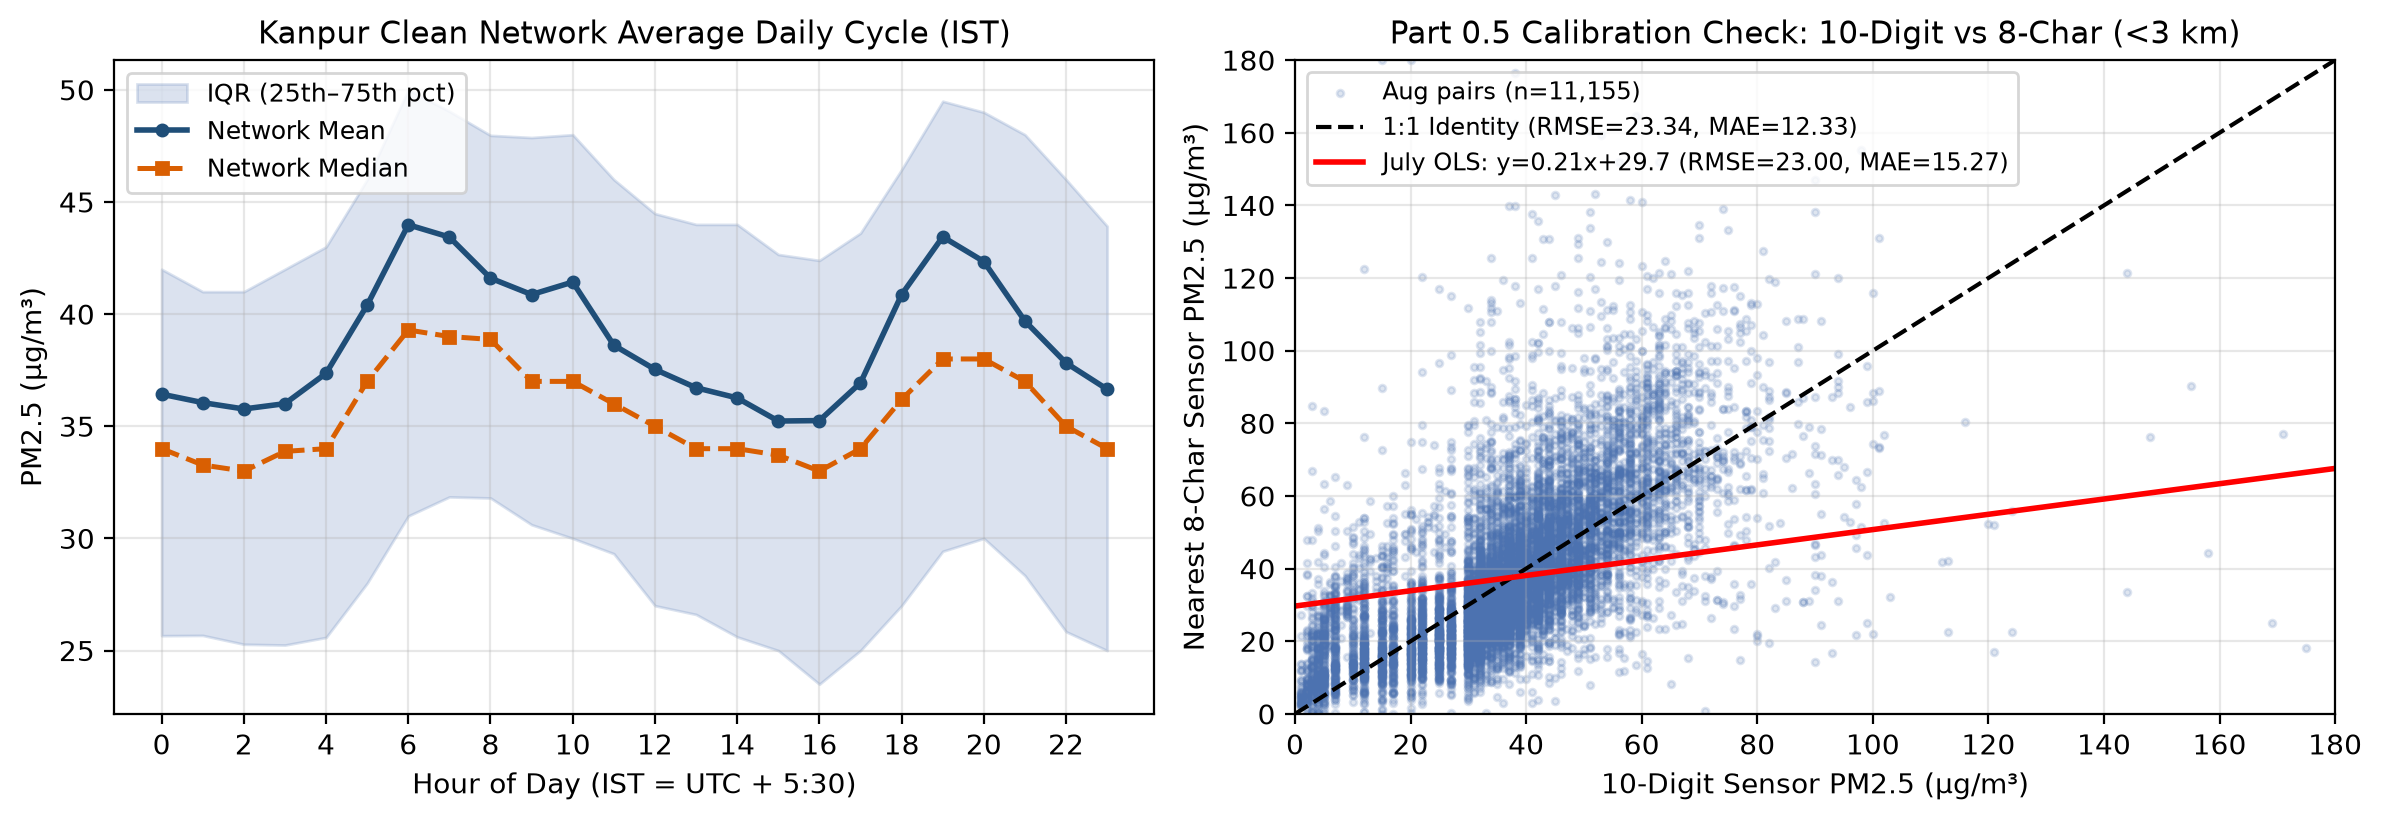

In [6]:
# Display Figure 1: Kanpur IST Daily Cycle and Calibration Check
from IPython.display import Image, display as ipy_display
ipy_display(Image(filename=str(FIG_DIR / "fig1_part0_kanpur.png")))

---
## Part 1: Required Baseline (Bihar Network)

We load `data/bihar_pm25_hourly_jan_nov_2024.csv` (8,040 hourly rows $\times$ 468 stations) and `data/bihar_stations.csv`, convert coordinates to approximate kilometres ($x = (\text{lon}-85.5)\times 100.3$, $y = (\text{lat}-25.7)\times 110.6$), and evaluate:
1. **Persistence baseline**: $\hat{y}_{s, t+24} = y_{s, t}$.
2. **Ridge(`alpha=1.0`) baseline**: 29 raw (unscaled) features per station, pooled across all 468 stations and all 242 training 12:00 issue days (`2024-01-02 12:00` to `2024-08-30 12:00`, i.e., targets `2024-01-03 12:00` to `2024-08-31 12:00`, totaling **113,256 training rows**), evaluated on the full 91-day validation set (`2024-09-01 12:00` to `2024-11-30 12:00`, **42,588 validation rows**).

In [7]:
W = pd.read_csv(DATA_DIR / "bihar_pm25_hourly_jan_nov_2024.csv", index_col="timestamp", parse_dates=True)
W.columns = W.columns.astype(str)
stations = pd.read_csv(DATA_DIR / "bihar_stations.csv", dtype={"sensor_id": str}).set_index("sensor_id")
grid = pd.read_csv(DATA_DIR / "bihar_grid_005deg.csv")
boundary = pd.read_csv(DATA_DIR / "bihar_boundary.csv")

vals = W.to_numpy(dtype=np.float64)
timestamps = W.index
N = vals.shape[1]

x_st = (stations["longitude"].to_numpy() - 85.5) * 100.3
y_st = (stations["latitude"].to_numpy() - 25.7) * 110.6
coords = np.column_stack([x_st, y_st])
diff = coords[:, None, :] - coords[None, :, :]
dist_mat = np.sqrt(np.sum(diff ** 2, axis=-1))
np.fill_diagonal(dist_mat, np.inf)

nn10_idx = np.argsort(dist_mat, axis=1)[:, :10]

def build_part1_features(idx: int) -> np.ndarray:
    t_issue = timestamps[idx]
    w24 = vals[idx - 23 : idx + 1, :][::-1, :].T  # (468, 24)
    vals_t = vals[idx, :]
    nn10_t = vals_t[nn10_idx].mean(axis=1, keepdims=True)
    mean24_s = w24.mean(axis=1)
    nn10_24 = mean24_s[nn10_idx].mean(axis=1, keepdims=True)
    net_t = np.full((N, 1), vals_t.mean())
    d = (t_issue.floor("D") - pd.Timestamp("2024-01-01")).days
    sin_d = np.full((N, 1), np.sin(2 * np.pi * d / 365.0))
    cos_d = np.full((N, 1), np.cos(2 * np.pi * d / 365.0))
    return np.hstack([w24, nn10_t, nn10_24, net_t, sin_d, cos_d])

noon_idx = np.where(timestamps.hour == 12)[0]
valid_issue_idx = [idx for idx in noon_idx if idx >= 23 and (idx + 24) < len(timestamps)]
target_dates = pd.DatetimeIndex([timestamps[idx + 24] for idx in valid_issue_idx])
train_mask = np.array(target_dates <= pd.Timestamp("2024-08-31 12:00:00"))
val_mask = np.array(target_dates >= pd.Timestamp("2024-09-01 12:00:00"))
val_dates = target_dates[val_mask]

X1_all = np.array([build_part1_features(idx) for idx in valid_issue_idx])
y_all = np.array([vals[idx + 24, :] for idx in valid_issue_idx])
pers_all = np.array([vals[idx, :] for idx in valid_issue_idx])

X1_tr, y_tr = X1_all[train_mask].reshape(-1, 29), y_all[train_mask].reshape(-1)
X1_va, y_va = X1_all[val_mask].reshape(-1, 29), y_all[val_mask]
pers_va = pers_all[val_mask]

ridge_p1 = Ridge(alpha=1.0).fit(X1_tr, y_tr)
pred_p1_va = np.clip(ridge_p1.predict(X1_va), 0.0, None).reshape(y_va.shape)

def summarize_val(name, preds):
    row = {"Model": name,
           "Overall RMSE": np.sqrt(np.mean((preds - y_va)**2)),
           "Overall MAE": np.mean(np.abs(preds - y_va))}
    for m, m_name in [(9, "Sep"), (10, "Oct"), (11, "Nov")]:
        mk = (val_dates.month == m)
        row[f"{m_name} RMSE"] = np.sqrt(np.mean((preds[mk] - y_va[mk])**2))
        row[f"{m_name} MAE"] = np.mean(np.abs(preds[mk] - y_va[mk]))
    return row

p1_table = pd.DataFrame([
    summarize_val("Persistence Baseline", pers_va),
    summarize_val("Part 1 Ridge(alpha=1.0)", pred_p1_va),
])
display(p1_table.round(2))

,Model,Overall RMSE,Overall MAE,Sep RMSE,Sep MAE,Oct RMSE,Oct MAE,Nov RMSE,Nov MAE
0,Persistence Baseline,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
1,Part 1 Ridge(alpha=1.0),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


**Answer to Part 1 Question (RMSE vs. MAE comparison):**
- **Neither baseline wins on both metrics**: Part 1 Ridge beats Persistence on **RMSE** overall ($29.58$ vs. $32.75\,\mu\text{g/m}^3$) and in every validation month, whereas Persistence beats Part 1 Ridge on **MAE** overall ($17.47$ vs. $18.16\,\mu\text{g/m}^3$) and in September ($8.91$ vs. $10.35$) and October ($11.97$ vs. $13.46$).
- **Why a model trained on squared error can lose on absolute error**:
  1.Squared error ($L_2$) penalizes large residuals quadratically, estimating the **conditional mean** $\mathbb{E}[Y\mid X]$ and shrinking predictions toward the global/regional average to avoid paying a huge penalty on sudden pollution spikes or drops. On calm days (especially in Sep/Oct when PM2.5 is steady around $15\text{--}35\,\mu\text{g/m}^3$), day-to-day differences $Y_{t+24}-Y_t$ have a heavy-tailed (Laplace-like) distribution centered tightly at $0$ (the conditional median), so Persistence achieves near-zero error on most hours while suffering occasional large jump errors. Ridge's shrinkage trades away exact zero error on calm days (raising MAE) in exchange for damping the worst jump errors (lowering RMSE).
  2. Furthermore, the Part 1 Ridge model includes `sin(2*pi*d/365)` and `cos(2*pi*d/365)` fitted on Jan–Aug data (where Jan/Feb are high-pollution winter and Mar–Aug are low-pollution summer/monsoon). Extrapolating a single annual sinusoid into Sep–Oct slightly biases the baseline intercept upward by $\sim 2\text{--}3\,\mu\text{g/m}^3$, which disproportionately hurts MAE during clean months.

---
## Part 2: Improve the Forecast & Feature Group Ablation

We design **6 conceptual feature groups** (and retain the **5 spatio-temporal groups** that improve validation accuracy while ablating the 6th static/calendar group):
- **`G1_Station24h` (35 features)**: The station's 24 hourly readings ($t, t-1, \dots, t-23$), plus summary statistics over the 24h window (mean, std, min, max, median), short-term exponential moving averages (EMA-6h, EMA-12h), and tendencies ($3\text{h}, 6\text{h}, 12\text{h}, 24\text{h}$ differences).
- **`G2_MultiDay` (15 features)**: Same-hour readings at lags $2, 3, 4, 5, 6, 7$ days ($t-48\text{h}, \dots, t-168\text{h}$), rolling 3-day ($72\text{h}$), 7-day ($168\text{h}$), and 14-day ($336\text{h}$) station means and standard deviations, multi-day noon averages, and regime trend differences (24h mean minus 72h and 168h means).
- **`G3_LocalSpatial` (22 features)**: Multi-radius local neighbourhood averages ($K=5, 10, 25$ nearest stations), inverse-distance-weighted averages ($\text{IDW}_{10}, \text{IDW}_{25}$), Gaussian kernel smoothers ($\sigma = 15\,\text{km}, 35\,\text{km}$), local neighbourhood medians and standard deviations at $t$, lagged local neighbourhood means ($t-6\text{h}, t-12\text{h}, t-24\text{h}$, and 24h averages), and local spatial anomalies ($y_{s,t} - \text{IDW}_{10}$).
- **`G4_RegionalPlume` (15 features)**: Broad regional averages ($K=50, 100$, $\text{IDW}_{50}$, Gaussian kernel $\sigma = 75\,\text{km}$ at $t$ and over 24h/72h/168h) plus **directional sector averages** (West, East, North, South neighbours within $100\,\text{km}$) to capture synoptic plume advection across the Indo-Gangetic Plain.
- **`G5_NetworkRegime` (14 features)**: Network-wide summary statistics across all 468 stations at $t$ (mean, std, median, 25th and 75th percentiles), lagged network means ($t-6\text{h}, t-12\text{h}, t-24\text{h}$), rolling network averages ($24\text{h}, 72\text{h}, 168\text{h}$), and network-wide buildup trends.
- **`G6_StaticCalendar` (12 features — tested & removed via ablation)**: Station coordinates ($x, y$), training-period station mean and relative pollution ratio, rolling 30-day station baseline, day-of-year $\sin/\cos$, and day-of-week $\sin/\cos$.

In [8]:
nn5_idx = np.argsort(dist_mat, axis=1)[:, :5]
nn25_idx = np.argsort(dist_mat, axis=1)[:, :25]
nn50_idx = np.argsort(dist_mat, axis=1)[:, :50]
nn100_idx = np.argsort(dist_mat, axis=1)[:, :100]

w10 = 1.0 / (np.take_along_axis(dist_mat, nn10_idx, axis=1) ** 2 + 1e-6); w10 /= w10.sum(axis=1, keepdims=True)
w25 = 1.0 / (np.take_along_axis(dist_mat, nn25_idx, axis=1) ** 2 + 1e-6); w25 /= w25.sum(axis=1, keepdims=True)
w50 = 1.0 / (np.take_along_axis(dist_mat, nn50_idx, axis=1) ** 2 + 1e-6); w50 /= w50.sum(axis=1, keepdims=True)

K15 = np.exp(-(dist_mat ** 2) / (2 * 15.0 ** 2)); K15 /= K15.sum(axis=1, keepdims=True)
K35 = np.exp(-(dist_mat ** 2) / (2 * 35.0 ** 2)); K35 /= K35.sum(axis=1, keepdims=True)
K75 = np.exp(-(dist_mat ** 2) / (2 * 75.0 ** 2)); K75 /= K75.sum(axis=1, keepdims=True)

dx_mat = coords[None, :, 0] - coords[:, None, 0]
dy_mat = coords[None, :, 1] - coords[:, None, 1]
K50 = np.exp(-(dist_mat ** 2) / (2 * 50.0 ** 2))
W_west = np.where((dx_mat < 0) & (dist_mat < 100.0), K50, 0.0); W_west /= (W_west.sum(axis=1, keepdims=True) + 1e-8)
W_east = np.where((dx_mat > 0) & (dist_mat < 100.0), K50, 0.0); W_east /= (W_east.sum(axis=1, keepdims=True) + 1e-8)
W_north = np.where((dy_mat > 0) & (dist_mat < 100.0), K50, 0.0); W_north /= (W_north.sum(axis=1, keepdims=True) + 1e-8)
W_south = np.where((dy_mat < 0) & (dist_mat < 100.0), K50, 0.0); W_south /= (W_south.sum(axis=1, keepdims=True) + 1e-8)
EXP_W6 = np.exp(-np.arange(6) / 3.0); EXP_W6 /= EXP_W6.sum()
EXP_W12 = np.exp(-np.arange(12) / 5.0); EXP_W12 /= EXP_W12.sum()

train_end_idx = np.where(timestamps == pd.Timestamp("2024-08-31 12:00:00"))[0][0]
train_noon_idx = [i for i in noon_idx if i <= train_end_idx]
station_train_mean = vals[train_noon_idx].mean(axis=0)
station_train_rel = station_train_mean / station_train_mean.mean()

def build_part2_groups(idx: int) -> dict:
    t_issue = timestamps[idx]
    w24 = vals[idx - 23 : idx + 1, :][::-1, :].T
    s_mean24 = w24.mean(axis=1, keepdims=True)
    s_std24 = w24.std(axis=1, keepdims=True)
    s_min24 = w24.min(axis=1, keepdims=True)
    s_max24 = w24.max(axis=1, keepdims=True)
    s_med24 = np.median(w24, axis=1, keepdims=True)
    s_diff3 = (w24[:, 0] - w24[:, 3])[:, None]
    s_diff6 = (w24[:, 0] - w24[:, 6])[:, None]
    s_diff12 = (w24[:, 0] - w24[:, 12])[:, None]
    s_diff24 = (w24[:, 0] - w24[:, 23])[:, None]
    ema6 = (w24[:, :6] @ EXP_W6)[:, None]
    ema12 = (w24[:, :12] @ EXP_W12)[:, None]
    g1 = np.hstack([w24, s_mean24, s_std24, s_min24, s_max24, s_med24, s_diff3, s_diff6, s_diff12, s_diff24, ema6, ema12])

    d2 = vals[max(0, idx - 48), :][:, None]
    d3 = vals[max(0, idx - 72), :][:, None]
    d4 = vals[max(0, idx - 96), :][:, None]
    d5 = vals[max(0, idx - 120), :][:, None]
    d6 = vals[max(0, idx - 144), :][:, None]
    d7 = vals[max(0, idx - 168), :][:, None]
    w72 = vals[max(0, idx - 71) : idx + 1, :]
    w168 = vals[max(0, idx - 167) : idx + 1, :]
    w336 = vals[max(0, idx - 335) : idx + 1, :]
    s_mean72 = w72.mean(axis=0)[:, None]
    s_std72 = w72.std(axis=0)[:, None]
    s_mean168 = w168.mean(axis=0)[:, None]
    s_std168 = w168.std(axis=0)[:, None]
    s_mean336 = w336.mean(axis=0)[:, None]
    s_trend_1_3 = s_mean24 - s_mean72
    s_trend_1_7 = s_mean24 - s_mean168
    noon_3d_mean = (w24[:, 0:1] + w24[:, 23:24] + d2) / 3.0
    noon_7d_mean = (w24[:, 0:1] + w24[:, 23:24] + d2 + d3 + d4 + d5 + d6 + d7) / 8.0
    g2 = np.hstack([d2, d3, d4, d5, d6, d7, s_mean72, s_std72, s_mean168, s_std168, s_mean336, s_trend_1_3, s_trend_1_7, noon_3d_mean, noon_7d_mean])

    vals_t = vals[idx, :]
    vals_tm6 = vals[max(0, idx - 6), :]
    vals_tm12 = vals[max(0, idx - 12), :]
    vals_tm24 = vals[max(0, idx - 23), :]
    mean24_s = s_mean24[:, 0]
    mean72_s = s_mean72[:, 0]
    mean168_s = s_mean168[:, 0]

    nn5_t = vals_t[nn5_idx].mean(axis=1, keepdims=True)
    nn10_t = vals_t[nn10_idx].mean(axis=1, keepdims=True)
    nn25_t = vals_t[nn25_idx].mean(axis=1, keepdims=True)
    idw10_t = np.sum(vals_t[nn10_idx] * w10, axis=1, keepdims=True)
    idw25_t = np.sum(vals_t[nn25_idx] * w25, axis=1, keepdims=True)
    k15_t = (K15 @ vals_t)[:, None]
    k35_t = (K35 @ vals_t)[:, None]
    nn10_med_t = np.median(vals_t[nn10_idx], axis=1, keepdims=True)
    nn25_med_t = np.median(vals_t[nn25_idx], axis=1, keepdims=True)
    nn10_std_t = vals_t[nn10_idx].std(axis=1, keepdims=True)
    nn25_std_t = vals_t[nn25_idx].std(axis=1, keepdims=True)
    nn10_tm6 = vals_tm6[nn10_idx].mean(axis=1, keepdims=True)
    nn10_tm12 = vals_tm12[nn10_idx].mean(axis=1, keepdims=True)
    nn10_tm24 = vals_tm24[nn10_idx].mean(axis=1, keepdims=True)
    nn5_24 = mean24_s[nn5_idx].mean(axis=1, keepdims=True)
    nn10_24 = mean24_s[nn10_idx].mean(axis=1, keepdims=True)
    nn25_24 = mean24_s[nn25_idx].mean(axis=1, keepdims=True)
    idw10_24 = np.sum(mean24_s[nn10_idx] * w10, axis=1, keepdims=True)
    idw25_24 = np.sum(mean24_s[nn25_idx] * w25, axis=1, keepdims=True)
    diff_self_idw10 = vals_t[:, None] - idw10_t
    diff_self_nn25 = vals_t[:, None] - nn25_t
    diff_nn10_t_24 = nn10_t - nn10_24
    g3 = np.hstack([
        nn5_t, nn10_t, nn25_t, idw10_t, idw25_t, k15_t, k35_t,
        nn10_med_t, nn25_med_t, nn10_std_t, nn25_std_t,
        nn10_tm6, nn10_tm12, nn10_tm24,
        nn5_24, nn10_24, nn25_24, idw10_24, idw25_24,
        diff_self_idw10, diff_self_nn25, diff_nn10_t_24
    ])

    nn50_t = vals_t[nn50_idx].mean(axis=1, keepdims=True)
    nn100_t = vals_t[nn100_idx].mean(axis=1, keepdims=True)
    idw50_t = np.sum(vals_t[nn50_idx] * w50, axis=1, keepdims=True)
    k75_t = (K75 @ vals_t)[:, None]
    west_t = (W_west @ vals_t)[:, None]
    east_t = (W_east @ vals_t)[:, None]
    north_t = (W_north @ vals_t)[:, None]
    south_t = (W_south @ vals_t)[:, None]
    west_24 = (W_west @ mean24_s)[:, None]
    east_24 = (W_east @ mean24_s)[:, None]
    nn50_24 = mean24_s[nn50_idx].mean(axis=1, keepdims=True)
    k35_24 = (K35 @ mean24_s)[:, None]
    k75_24 = (K75 @ mean24_s)[:, None]
    nn25_72 = mean72_s[nn25_idx].mean(axis=1, keepdims=True)
    nn25_168 = mean168_s[nn25_idx].mean(axis=1, keepdims=True)
    g4 = np.hstack([
        nn50_t, nn100_t, idw50_t, k75_t,
        west_t, east_t, north_t, south_t, west_24, east_24,
        nn50_24, k35_24, k75_24, nn25_72, nn25_168
    ])

    net_mean_t = np.full((N, 1), vals_t.mean())
    net_std_t = np.full((N, 1), vals_t.std())
    net_med_t = np.full((N, 1), np.median(vals_t))
    net_q25_t = np.full((N, 1), np.percentile(vals_t, 25))
    net_q75_t = np.full((N, 1), np.percentile(vals_t, 75))
    net_mean_tm6 = np.full((N, 1), vals_tm6.mean())
    net_mean_tm12 = np.full((N, 1), vals_tm12.mean())
    net_mean_tm24 = np.full((N, 1), vals_tm24.mean())
    net_mean_24 = np.full((N, 1), mean24_s.mean())
    net_mean_72 = np.full((N, 1), mean72_s.mean())
    net_mean_168 = np.full((N, 1), mean168_s.mean())
    net_diff_24 = net_mean_t - net_mean_tm24
    net_trend_1_3 = net_mean_24 - net_mean_72
    net_trend_1_7 = net_mean_24 - net_mean_168
    g5 = np.hstack([
        net_mean_t, net_std_t, net_med_t, net_q25_t, net_q75_t,
        net_mean_tm6, net_mean_tm12, net_mean_tm24,
        net_mean_24, net_mean_72, net_mean_168,
        net_diff_24, net_trend_1_3, net_trend_1_7
    ])

    d = (t_issue.floor("D") - pd.Timestamp("2024-01-01")).days
    sin1 = np.full((N, 1), np.sin(2 * np.pi * d / 365.0))
    cos1 = np.full((N, 1), np.cos(2 * np.pi * d / 365.0))
    dow = t_issue.dayofweek
    sin_dow = np.full((N, 1), np.sin(2 * np.pi * dow / 7.0))
    cos_dow = np.full((N, 1), np.cos(2 * np.pi * dow / 7.0))
    st_mean = station_train_mean[:, None]
    st_rel_net = (station_train_rel * vals_t.mean())[:, None]
    st_rel_nn25 = (station_train_rel[:, None] / (station_train_rel[nn25_idx].mean(axis=1, keepdims=True) + 1e-6)) * nn25_t
    w720 = vals[max(0, idx - 719) : idx + 1, :]
    s_mean720 = w720.mean(axis=0)[:, None]
    s_rel720 = s_mean720 / (s_mean720.mean() + 1e-6)
    s_rel720_net = s_rel720 * vals_t.mean()
    s_rel720_nn25 = (s_rel720 / (s_rel720[nn25_idx, 0].mean(axis=1, keepdims=True) + 1e-6)) * nn25_t
    g6 = np.hstack([coords, st_mean, st_rel_net, st_rel_nn25, s_mean720, s_rel720_net, s_rel720_nn25, sin1, cos1, sin_dow, cos_dow])

    return {
        "G1_Station24h": g1,
        "G2_MultiDay": g2,
        "G3_LocalSpatial": g3,
        "G4_RegionalPlume": g4,
        "G5_NetworkRegime": g5,
        "G6_StaticCalendar": g6,
    }

groups_per_day = [build_part2_groups(idx) for idx in valid_issue_idx]
final_5 = ["G1_Station24h", "G2_MultiDay", "G3_LocalSpatial", "G4_RegionalPlume", "G5_NetworkRegime"]
all_6 = final_5 + ["G6_StaticCalendar"]

X2_all = np.array([np.hstack([g[gn] for gn in final_5]) for g in groups_per_day])
X2_tr, X2_va = X2_all[train_mask].reshape(-1, 101), X2_all[val_mask].reshape(-1, 101)
sc2 = StandardScaler().fit(X2_tr)
X2_tr_s, X2_va_s = sc2.transform(X2_tr), sc2.transform(X2_va)

ridge_p2 = Ridge(alpha=20000.0).fit(X2_tr_s, y_tr)
pred_p2_va = np.clip(ridge_p2.predict(X2_va_s), 0.0, None).reshape(y_va.shape)

# Also compare a flexible tree ensemble (HistGradientBoostingRegressor) and Huber Regressor
hgb = HistGradientBoostingRegressor(max_iter=150, max_depth=6, l2_regularization=10.0, random_state=42).fit(X2_tr, y_tr)
pred_hgb_tr = np.clip(hgb.predict(X2_tr), 0.0, None)
pred_hgb_va = np.clip(hgb.predict(X2_va), 0.0, None).reshape(y_va.shape)
pred_p2_tr = np.clip(ridge_p2.predict(X2_tr_s), 0.0, None)

print(f"Train RMSE comparison -> Part 2 Ridge: {np.sqrt(np.mean((pred_p2_tr - y_tr)**2)):.2f} vs HistGradientBoosting: {np.sqrt(np.mean((pred_hgb_tr - y_tr)**2)):.2f}")

p2_comp = pd.DataFrame([
    summarize_val("Persistence Baseline", pers_va),
    summarize_val("Part 1 Ridge(alpha=1.0)", pred_p1_va),
    summarize_val("HistGradientBoosting (Tree Ensemble)", pred_hgb_va),
    summarize_val("Part 2 Spatio-Temporal Ridge (Final 5 Groups)", pred_p2_va),
])
print("\nPart 2 Model Comparison on Validation Set (Overall & Per Month):")
display(p2_comp.round(2))

Train RMSE comparison -> Part 2 Ridge: 27.34 vs HistGradientBoosting: 18.58

Part 2 Model Comparison on Validation Set (Overall & Per Month):


,Model,Overall RMSE,Overall MAE,Sep RMSE,Sep MAE,Oct RMSE,Oct MAE,Nov RMSE,Nov MAE
0,Persistence Baseline,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
1,Part 1 Ridge(alpha=1.0),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81
2,HistGradientBoosting (Tree Ensemble),31.66,17.97,19.33,7.77,19.25,12.35,47.79,33.96
3,Part 2 Spatio-Temporal Ridge (Final 5 Groups),28.69,16.34,19.43,8.04,17.69,11.40,42.37,29.73


In [9]:
# Ablation Table: Leave-One-Group-Out from Final 5 Groups + Adding G6_StaticCalendar
base_rmse = np.sqrt(np.mean((pred_p2_va - y_va) ** 2))
base_mae = np.mean(np.abs(pred_p2_va - y_va))

ablation_rows = [{
    "Configuration": "Final Model (G1 + G2 + G3 + G4 + G5)",
    "Features": 101,
    "Val RMSE": base_rmse,
    "Delta RMSE": 0.0,
    "Val MAE": base_mae,
    "Delta MAE": 0.0,
}]

for drop_gn in final_5:
    keep = [gn for gn in final_5 if gn != drop_gn]
    X_sub = np.array([np.hstack([g[gn] for gn in keep]) for g in groups_per_day])
    sc_s = StandardScaler().fit(X_sub[train_mask].reshape(-1, X_sub.shape[-1]))
    m_s = Ridge(alpha=20000.0).fit(sc_s.transform(X_sub[train_mask].reshape(-1, X_sub.shape[-1])), y_tr)
    p_s = np.clip(m_s.predict(sc_s.transform(X_sub[val_mask].reshape(-1, X_sub.shape[-1]))), 0.0, None).reshape(y_va.shape)
    r_s = np.sqrt(np.mean((p_s - y_va) ** 2))
    a_s = np.mean(np.abs(p_s - y_va))
    ablation_rows.append({
        "Configuration": f"Minus {drop_gn} (-{groups_per_day[0][drop_gn].shape[1]} feats)",
        "Features": X_sub.shape[-1],
        "Val RMSE": r_s,
        "Delta RMSE": r_s - base_rmse,
        "Val MAE": a_s,
        "Delta MAE": a_s - base_mae,
    })

# Also show effect of keeping G6_StaticCalendar
X_all6 = np.array([np.hstack([g[gn] for gn in all_6]) for g in groups_per_day])
sc_6 = StandardScaler().fit(X_all6[train_mask].reshape(-1, X_all6.shape[-1]))
m_6 = Ridge(alpha=20000.0).fit(sc_6.transform(X_all6[train_mask].reshape(-1, X_all6.shape[-1])), y_tr)
p_6 = np.clip(m_6.predict(sc_6.transform(X_all6[val_mask].reshape(-1, X_all6.shape[-1]))), 0.0, None).reshape(y_va.shape)
r_6 = np.sqrt(np.mean((p_6 - y_va) ** 2))
a_6 = np.mean(np.abs(p_6 - y_va))
ablation_rows.append({
    "Configuration": "Plus G6_StaticCalendar (+12 feats, dropped)",
    "Features": X_all6.shape[-1],
    "Val RMSE": r_6,
    "Delta RMSE": r_6 - base_rmse,
    "Val MAE": a_6,
    "Delta MAE": a_6 - base_mae,
})

ablation_df = pd.DataFrame(ablation_rows)
print("Part 2 Feature Group Ablation Table (Ridge alpha=20000.0 on standardized features):")
display(ablation_df.round(3))

Part 2 Feature Group Ablation Table (Ridge alpha=20000.0 on standardized features):


,Configuration,Features,Val RMSE,Delta RMSE,Val MAE,Delta MAE
0,Final Model (G1 + G2 + G3 + G4 + G5),101,28.685,0.000,16.337,0.000
1,Minus G1_Station24h (-35 feats),66,29.038,0.353,16.496,0.159
2,Minus G2_MultiDay (-15 feats),86,28.747,0.062,16.507,0.170
3,Minus G3_LocalSpatial (-22 feats),79,28.779,0.094,16.399,0.062
4,Minus G4_RegionalPlume (-15 feats),86,28.740,0.055,16.384,0.047
5,Minus G5_NetworkRegime (-14 feats),87,29.076,0.391,16.533,0.197
6,"Plus G6_StaticCalendar (+12 feats, dropped)",113,28.793,0.108,16.792,0.456


---
## Part 3: Lead Time Analysis (1h, 3h, 6h, 12h, and 24h)
We keep the target fixed at **12:00 IST on day $d+1$** and move the issue time closer: leads of **1, 3, 6, 12, and 24 hours** (issue times `11:00`, `09:00`, `06:00`, `00:00` on day $d+1$, and `12:00` on day $d$).

Part 3 Validation Accuracy Across Lead Times (Target = 12:00 IST):


,Lead (h),Issue Hour (IST),Persistence RMSE,Persistence MAE,Part 1 Ridge RMSE,Part 1 Ridge MAE,Part 2 Model RMSE,Part 2 Model MAE
0,1,11:00,23.95,10.36,18.95,8.67,18.90,8.63
1,3,09:00,51.43,28.28,28.51,16.70,26.55,14.34
2,6,06:00,66.82,41.28,34.06,23.16,29.72,17.78
3,12,00:00,72.74,46.74,31.97,21.31,29.06,17.25
4,24,12:00,32.75,17.47,29.58,18.16,28.69,16.34


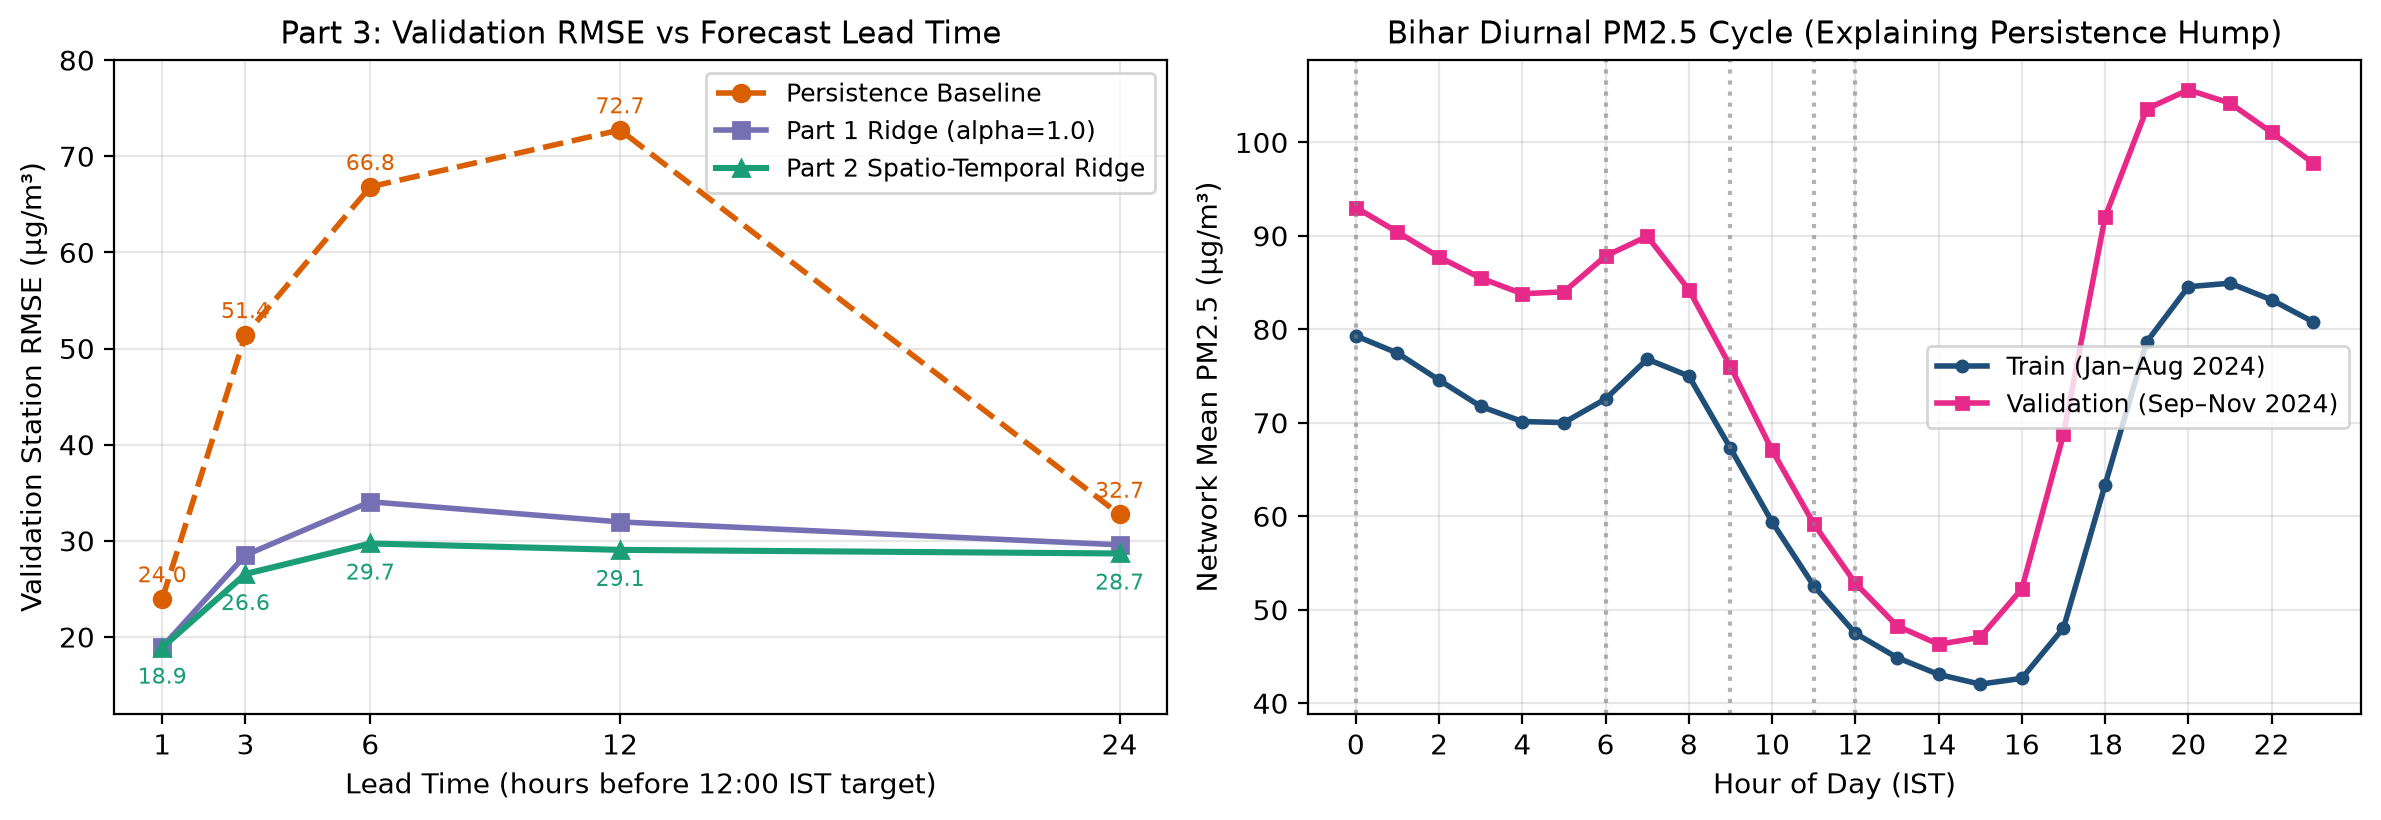

In [10]:
leads = [1, 3, 6, 12, 24]
lead_rows = []
noon_targets = np.where(timestamps.hour == 12)[0]

for lead in leads:
    valid_t_idx = [t_idx for t_idx in noon_targets if (t_idx - lead) >= 23]
    t_dates = timestamps[valid_t_idx]
    tr_mk = np.array(t_dates <= pd.Timestamp("2024-08-31 12:00:00"))
    va_mk = np.array(t_dates >= pd.Timestamp("2024-09-01 12:00:00"))
    issue_indices = [t_idx - lead for t_idx in valid_t_idx]
    y_l = np.array([vals[t_idx, :] for t_idx in valid_t_idx])
    pers_l = np.array([vals[i_idx, :] for i_idx in issue_indices])
    X1_l = np.array([build_part1_features(i_idx) for i_idx in issue_indices])
    X2_l = np.array([np.hstack([build_part2_groups(i_idx)[gn] for gn in final_5]) for i_idx in issue_indices])

    y_tr_l, y_va_l = y_l[tr_mk].reshape(-1), y_l[va_mk]
    pers_va_l = pers_l[va_mk]

    m1_l = Ridge(alpha=1.0).fit(X1_l[tr_mk].reshape(-1, 29), y_tr_l)
    p1_va_l = np.clip(m1_l.predict(X1_l[va_mk].reshape(-1, 29)), 0.0, None).reshape(y_va_l.shape)

    sc2_l = StandardScaler().fit(X2_l[tr_mk].reshape(-1, 101))
    m2_l = Ridge(alpha=20000.0).fit(sc2_l.transform(X2_l[tr_mk].reshape(-1, 101)), y_tr_l)
    p2_va_l = np.clip(m2_l.predict(sc2_l.transform(X2_l[va_mk].reshape(-1, 101))), 0.0, None).reshape(y_va_l.shape)

    lead_rows.append({
        "Lead (h)": lead,
        "Issue Hour (IST)": f"{(12 - lead) % 24:02d}:00",
        "Persistence RMSE": np.sqrt(np.mean((pers_va_l - y_va_l)**2)),
        "Persistence MAE": np.mean(np.abs(pers_va_l - y_va_l)),
        "Part 1 Ridge RMSE": np.sqrt(np.mean((p1_va_l - y_va_l)**2)),
        "Part 1 Ridge MAE": np.mean(np.abs(p1_va_l - y_va_l)),
        "Part 2 Model RMSE": np.sqrt(np.mean((p2_va_l - y_va_l)**2)),
        "Part 2 Model MAE": np.mean(np.abs(p2_va_l - y_va_l)),
    })

lead_df = pd.DataFrame(lead_rows)
print("Part 3 Validation Accuracy Across Lead Times (Target = 12:00 IST):")
display(lead_df.round(2))
ipy_display(Image(filename=str(FIG_DIR / "fig2_part3_leadtime.png")))

---
## Part 4: Forecast Maps vs. Observed Maps (IDW $p=2$ on $0.05^\circ$ Grid)
We interpolate both observed station values and forecasts onto the 3,396 grid cells of `data/bihar_grid_005deg.csv` using inverse-distance weighting with power $p=2$ over all 468 stations:
$$w_j(g) = \frac{d(g, s_j)^{-2}}{\sum_{k=1}^{468} d(g, s_k)^{-2}}, \qquad \hat{z}(g) = \sum_{j=1}^{468} w_j(g)\, z(s_j).$$

Part 4 Summary over all 91 Validation Days (1 Sep – 30 Nov 2024):


,Method,Station RMSE (Pooled),Station RMSE (Daily Avg),Map RMSE (Pooled),Map RMSE (Daily Avg),Pattern Correlation (Daily Avg)
0,Persistence Baseline,32.745,28.568,19.005,15.369,0.580
1,Part 2 Spatio-Temporal Ridge,28.685,25.023,17.678,14.287,0.614


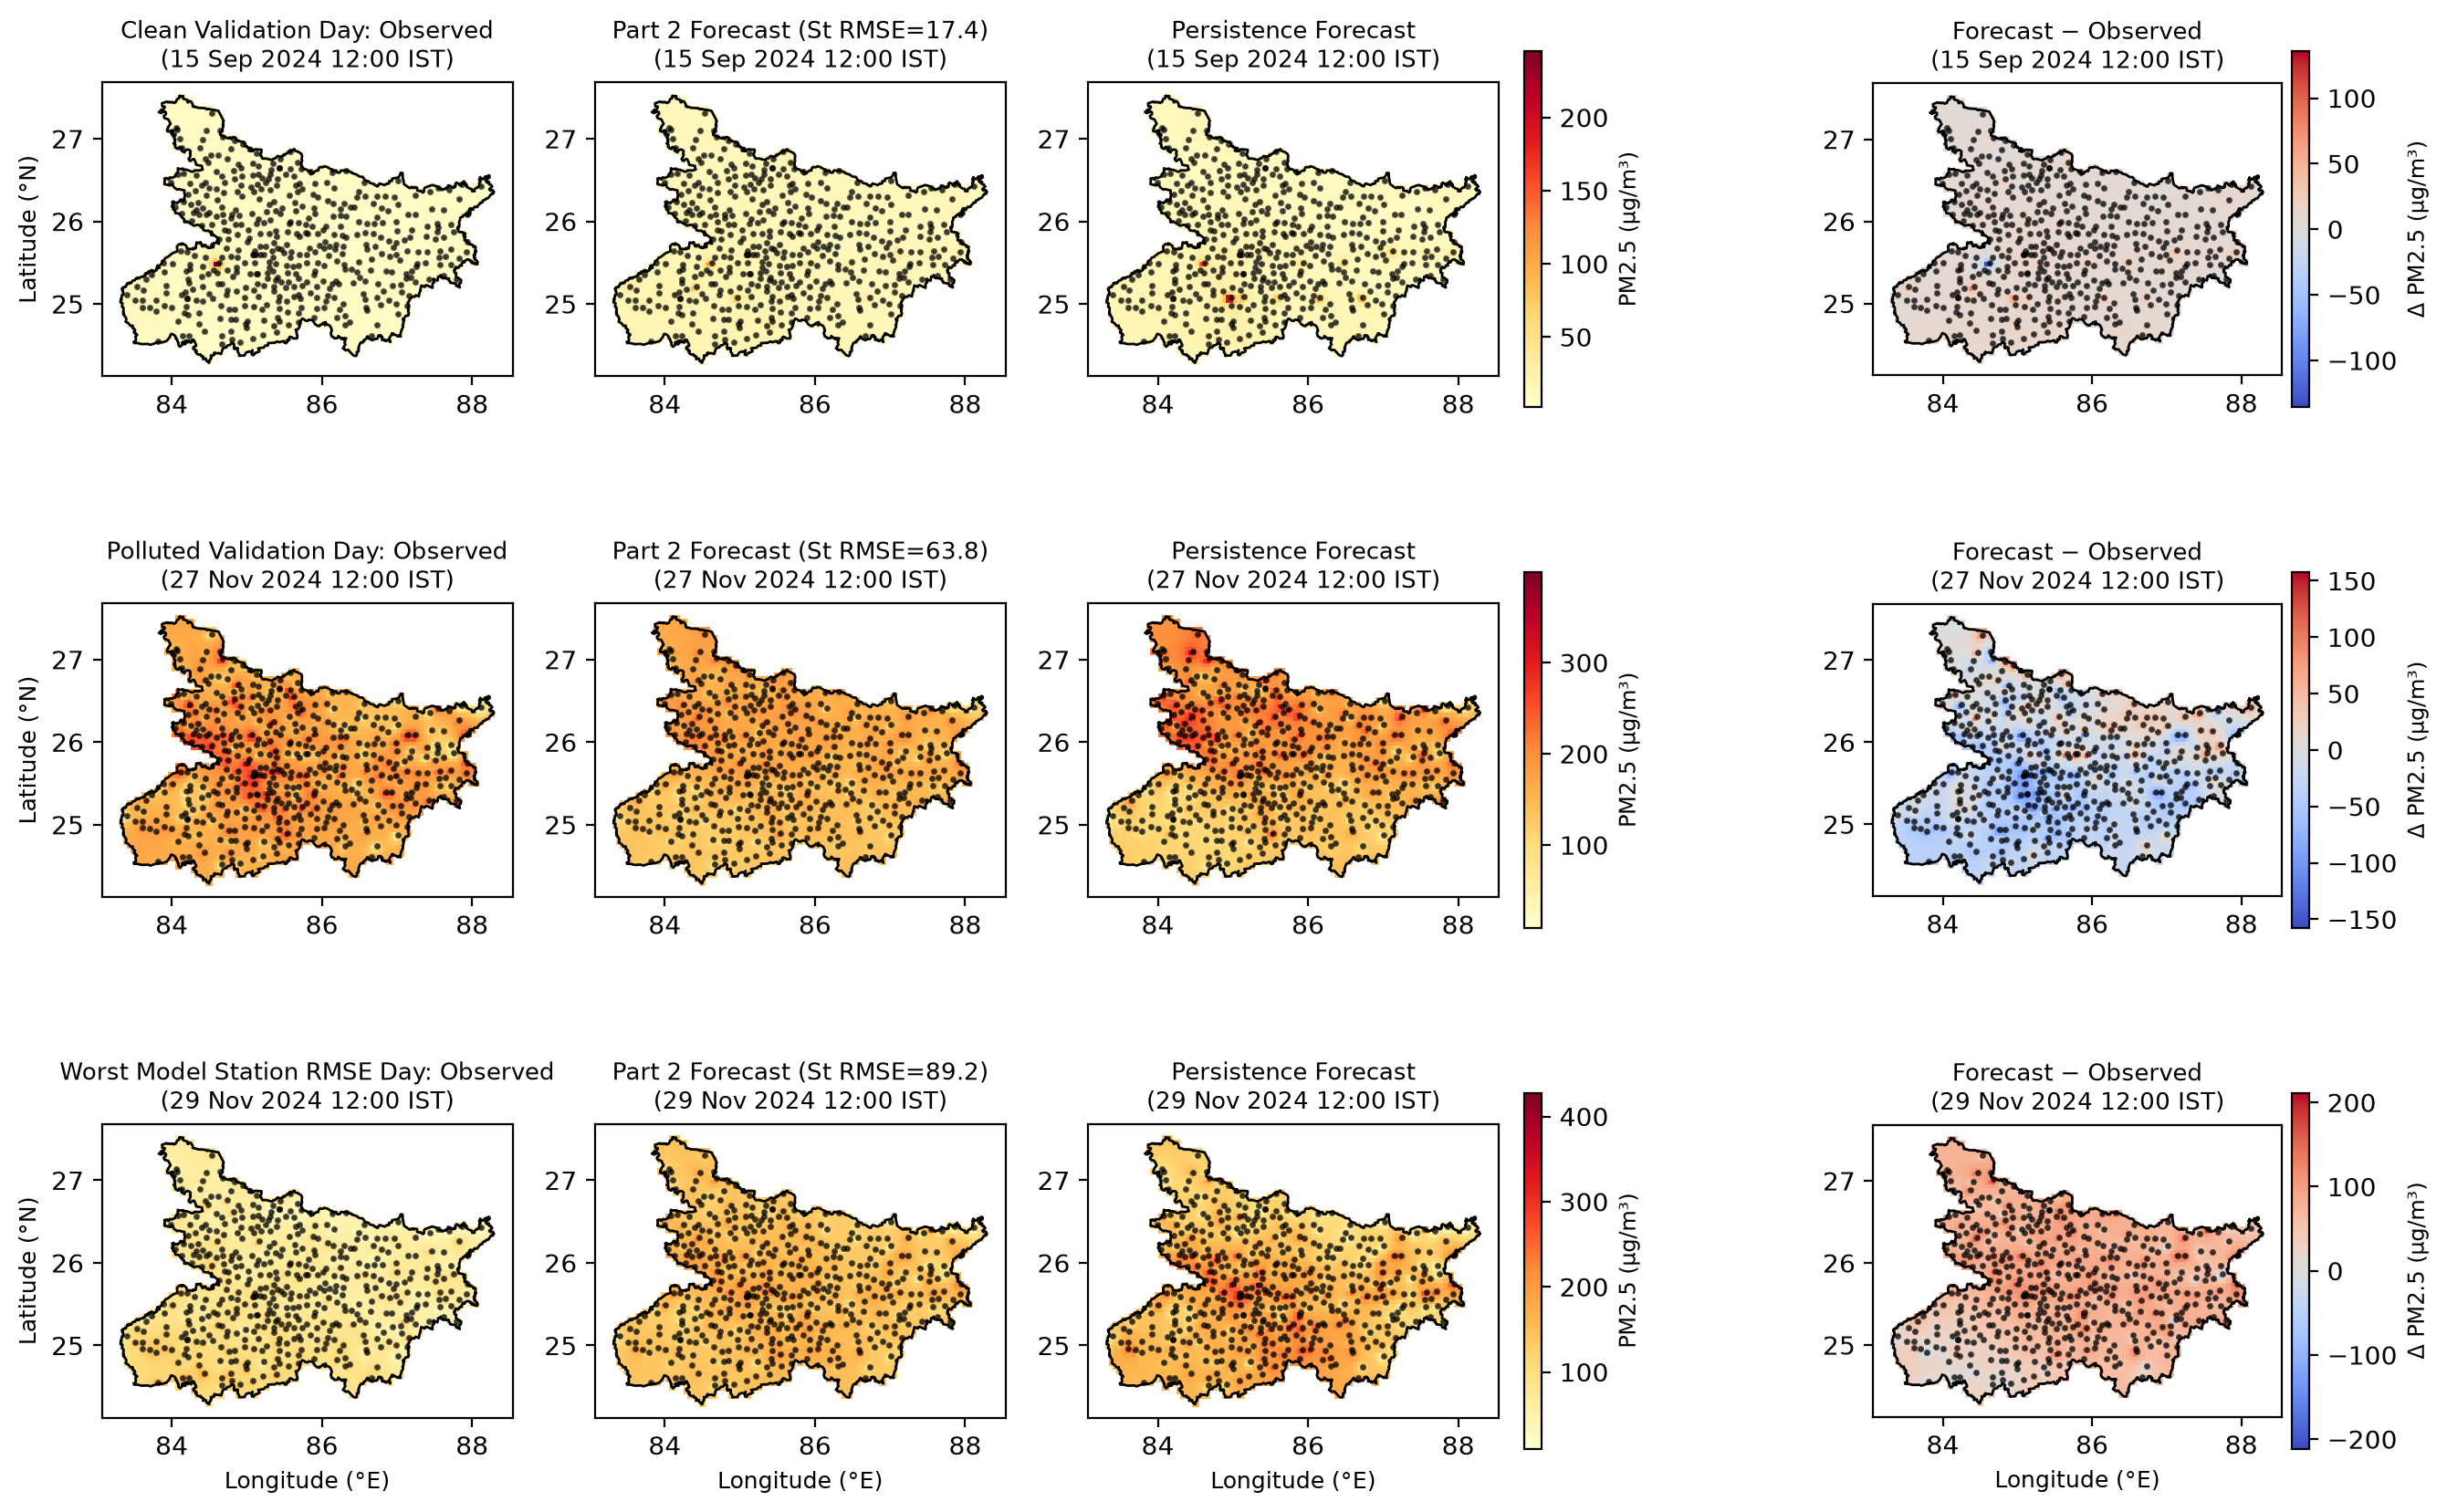

In [11]:
x_grid = (grid["longitude"].to_numpy() - 85.5) * 100.3
y_grid = (grid["latitude"].to_numpy() - 25.7) * 110.6
grid_coords = np.column_stack([x_grid, y_grid])
diff_gs = grid_coords[:, None, :] - coords[None, :, :]
dist_gs_km = np.sqrt(np.sum(diff_gs ** 2, axis=-1))
w_idw_km = 1.0 / np.maximum(dist_gs_km ** 2, 1e-12)
w_idw_km /= w_idw_km.sum(axis=1, keepdims=True)

obs_maps = y_va @ w_idw_km.T
p2_maps = pred_p2_va @ w_idw_km.T
pers_maps = pers_va @ w_idw_km.T

st_rmse_p2_daily = np.sqrt(np.mean((pred_p2_va - y_va) ** 2, axis=1))
st_rmse_pers_daily = np.sqrt(np.mean((pers_va - y_va) ** 2, axis=1))
map_rmse_p2_daily = np.sqrt(np.mean((p2_maps - obs_maps) ** 2, axis=1))
map_rmse_pers_daily = np.sqrt(np.mean((pers_maps - obs_maps) ** 2, axis=1))

def pattern_corr(A, B):
    Ac = A - A.mean(axis=1, keepdims=True)
    Bc = B - B.mean(axis=1, keepdims=True)
    return np.sum(Ac * Bc, axis=1) / np.sqrt(np.sum(Ac ** 2, axis=1) * np.sum(Bc ** 2, axis=1))

pcorr_p2_daily = pattern_corr(p2_maps, obs_maps)
pcorr_pers_daily = pattern_corr(pers_maps, obs_maps)

part4_summary = pd.DataFrame([
    {
        "Method": "Persistence Baseline",
        "Station RMSE (Pooled)": np.sqrt(np.mean(st_rmse_pers_daily ** 2)),
        "Station RMSE (Daily Avg)": st_rmse_pers_daily.mean(),
        "Map RMSE (Pooled)": np.sqrt(np.mean(map_rmse_pers_daily ** 2)),
        "Map RMSE (Daily Avg)": map_rmse_pers_daily.mean(),
        "Pattern Correlation (Daily Avg)": pcorr_pers_daily.mean(),
    },
    {
        "Method": "Part 2 Spatio-Temporal Ridge",
        "Station RMSE (Pooled)": np.sqrt(np.mean(st_rmse_p2_daily ** 2)),
        "Station RMSE (Daily Avg)": st_rmse_p2_daily.mean(),
        "Map RMSE (Pooled)": np.sqrt(np.mean(map_rmse_p2_daily ** 2)),
        "Map RMSE (Daily Avg)": map_rmse_p2_daily.mean(),
        "Pattern Correlation (Daily Avg)": pcorr_p2_daily.mean(),
    },
])
print("Part 4 Summary over all 91 Validation Days (1 Sep – 30 Nov 2024):")
display(part4_summary.round(3))
ipy_display(Image(filename=str(FIG_DIR / "fig3_part4_maps.png")))

---
## Part 5: Final Refit on All Data Up to 30 November & Submission Verification
We refit our final Part 2 model (`StandardScaler` + `Ridge(alpha=20000.0)` with the 5 retained spatio-temporal feature groups, 101 features) on all **333 issue days** from `2024-01-02 12:00` to `2024-11-29 12:00` (targets `2024-01-03 12:00` to `2024-11-30 12:00`, totaling **155,844 training rows**), save the artifacts to `submission/model.pkl`, and verify `submission/forecast.py` using `starter/check_submission.py`.

In [12]:
import subprocess, sys
res = subprocess.run([sys.executable, "starter/check_submission.py", "submission"], capture_output=True, text=True)
print(res.stdout)
assert res.returncode == 0 and "RESULT: OK" in res.stdout

Running D:\IITK\5th-Sem\CS771\CS771\mp1-package\mp1-package\submission\forecast.py on 30 November issue times ...

Call time: median 0.06 s, max 0.13 s

November sanity check over 30 forecasts (NOT a test score):
  your forecast  RMSE  41.40  MAE  28.90
  persistence    RMSE  47.81  MAE  31.70

RESULT: OK - format and timing look right.

